# Task 2

# 1. Imports, Random Seed Initialization, and Class Imbalance Inspection


In [1]:
import os
import pickle
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("NOTE: 'xgboost' not installed; using HistGradientBoostingClassifier with sample weights.")

warnings.filterwarnings("ignore")

# Fix all random seeds for reproducibility (Section 4 requirement)
SEED = 42
np.random.seed(SEED)
N_WORKERS = max(1, (os.cpu_count() or 4) - 1)

# Load Task 2 dataset and preserve the exact 80/20 stratified train/test split
df_task2 = pd.read_csv("promoter_assignment_data/task2_sigma.csv")
train_df = df_task2[df_task2["split"] == "train"].reset_index(drop=True)
test_df  = df_task2[df_task2["split"] == "test"].reset_index(drop=True)

# Order classes from largest to smallest support for clear confusion matrix visualization
SIGMA_CLASSES = ["sigma70", "sigma24", "sigma32", "sigma38", "sigma28", "sigma54"]
label_to_idx = {s: i for i, s in enumerate(SIGMA_CLASSES)}
idx_to_label = {i: s for i, s in enumerate(SIGMA_CLASSES)}

X_train_seqs = train_df["sequence"].tolist()
y_train      = np.array([label_to_idx[s] for s in train_df["sigma"]])
X_test_seqs  = test_df["sequence"].tolist()
y_test       = np.array([label_to_idx[s] for s in test_df["sigma"]])

# Display class distribution and imbalance ratio
dist_rows = []
for i, s in enumerate(SIGMA_CLASSES):
    tr_n = int(np.sum(y_train == i))
    te_n = int(np.sum(y_test == i))
    tot_n = tr_n + te_n
    dist_rows.append({
        "Sigma Factor": s,
        "Train Count": tr_n,
        "Test Count": te_n,
        "Total": tot_n,
        "Share (%)": 100.0 * tot_n / len(df_task2),
    })
dist_df = pd.DataFrame(dist_rows)
print("=== Task 2 Dataset Class Distribution ===")
print(dist_df.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

imbalance_ratio = dist_df["Total"].max() / dist_df["Total"].min()
majority_acc = np.sum(y_test == 0) / len(y_test)
print(f"\nLargest-to-Smallest Class Imbalance Ratio: {imbalance_ratio:.2f} : 1 (sigma70 vs. sigma54)")
print(f"Dummy Majority-Class Classifier Accuracy on Test Set: {majority_acc:.4f} (with 0.00 recall on all 5 minority classes!)")


=== Task 2 Dataset Class Distribution ===
Sigma Factor  Train Count  Test Count  Total  Share (%)
     sigma70         1354         339   1693      59.24
     sigma24          387          97    484      16.93
     sigma32          233          58    291      10.18
     sigma38          130          33    163       5.70
     sigma28          107          27    134       4.69
     sigma54           75          18     93       3.25

Largest-to-Smallest Class Imbalance Ratio: 18.20 : 1 (sigma70 vs. sigma54)
Dummy Majority-Class Classifier Accuracy on Test Set: 0.5927 (with 0.00 recall on all 5 minority classes!)


# 2. Feature Engineering: k-mers, Composition, Windows & Sigma-Specific Motifs


In [2]:
NUCLEOTIDES = ["A", "C", "G", "T"]

def extract_kmer_features(sequences, k=3):
    """
    Computes normalized overlapping k-mer frequency vectors of length 4^k.
    Uses k=3 (64 features), which achieved peak 5-fold CV performance in Task 1.
    """
    kmers = ["".join(p) for p in product(NUCLEOTIDES, repeat=k)]
    kmer_to_idx = {km: i for i, km in enumerate(kmers)}
    n_kmers = len(kmers)
    
    X = np.zeros((len(sequences), n_kmers), dtype=np.float32)
    for row_idx, seq in enumerate(sequences):
        total_windows = len(seq) - k + 1
        for i in range(total_windows):
            km = seq[i : i + k]
            if km in kmer_to_idx:
                X[row_idx, kmer_to_idx[km]] += 1.0
        X[row_idx] /= total_windows
    return X, [f"kmer_{km}" for km in kmers]


def pwm_log_odds_score(seq_window, consensus, match_prob=0.75, bg_prob=0.25):
    """
    Computes log-odds match score (bits) against a canonical consensus motif.
    Wildcard 'N' positions contribute 0 bits.
    """
    score = 0.0
    mismatch_prob = (1.0 - match_prob) / 3.0
    for base, cons_base in zip(seq_window, consensus):
        if cons_base == "N":
            continue
        p = match_prob if base == cons_base else mismatch_prob
        score += np.log2(p / bg_prob)
    return score


def max_motif_score_in_window(seq, start_idx, end_idx, consensus):
    """
    Finds the highest consensus motif log-odds score inside a biologically relevant
    coordinate range [start_idx, end_idx) relative to the +1 TSS (index 60).
    """
    w = len(consensus)
    best_score = -1e9
    for i in range(start_idx, end_idx - w + 1):
        s = pwm_log_odds_score(seq[i : i + w], consensus)
        if s > best_score:
            best_score = s
    return best_score


def extract_domain_and_positional_features(sequences):
    """
    Applies the same Task 1 biological feature-engineering framework extended with
    consensus motif detectors for all six E. coli sigma factors:
      1. Global nucleotide frequencies, GC content, GC skew, AT skew (7 features)
      2. TSS-aligned 6-zone window compositions + localized -35/-10 dinucleotides (62 features)
      3. Biophysical SantaLucia DNA duplex melting free energy (dG_37) across promoter zones (5 features)
      4. Canonical motif log-odds scores for all 6 sigma factors (12 features):
         - sigma70: -35 (TTGACA), -10 (TATAAT), extended -10 (TGNTATAAT)
         - sigma24: -35 (GAACTT), -10 (TCTGA)
         - sigma32: -35 (CTTGAAA), -10 (CCCCATNT)
         - sigma38: -10 (CTATACT)
         - sigma28: -35 (TAAAGTTT), -10 (GCCGATAA)
         - sigma54: -24 (TGGCAC), -12 (TTGCA)
    """
    dG_map = {
        "AA": -1.00, "TT": -1.00, "AT": -0.88, "TA": -0.58,
        "CA": -1.45, "TG": -1.45, "GT": -1.44, "AC": -1.44,
        "CT": -1.28, "AG": -1.28, "GA": -1.30, "TC": -1.30,
        "CG": -2.17, "GC": -2.24, "GG": -1.84, "CC": -1.84,
    }
    dinucs = ["".join(p) for p in product(NUCLEOTIDES, repeat=2)]
    dinuc_idx = {d: i for i, d in enumerate(dinucs)}

    windows = [
        ("up_far", 0, 20),
        ("box35", 20, 35),
        ("spacer", 35, 45),
        ("box10", 45, 56),
        ("tss", 56, 66),
        ("down", 66, 81),
    ]

    feature_names = ["global_A", "global_C", "global_G", "global_T", "global_GC", "global_GC_skew", "global_AT_skew"]
    for w_name, _, _ in windows:
        feature_names.extend([f"{w_name}_A", f"{w_name}_C", f"{w_name}_G", f"{w_name}_T", f"{w_name}_GC"])
    feature_names.extend([f"box35_dinuc_{d}" for d in dinucs])
    feature_names.extend([f"box10_dinuc_{d}" for d in dinucs])
    feature_names.extend([
        "motif_s70_35", "motif_s70_10", "motif_ext10",
        "motif_s24_35", "motif_s24_10",
        "motif_s32_35", "motif_s32_10",
        "motif_s38_10",
        "motif_s28_35", "motif_s28_10",
        "motif_s54_24", "motif_s54_12",
        "dG_global", "dG_box35", "dG_box10_melting", "dG_tss", "dG_destabilization_10_vs_global"
    ])

    feats = np.zeros((len(sequences), len(feature_names)), dtype=np.float32)

    for row_idx, seq in enumerate(sequences):
        L = len(seq)
        a, c, g, t = seq.count("A")/L, seq.count("C")/L, seq.count("G")/L, seq.count("T")/L
        gc = g + c
        gc_skew = (g - c) / (g + c + 1e-8)
        at_skew = (a - t) / (a + t + 1e-8)

        win_vals = []
        for _, w_s, w_e in windows:
            sub = seq[w_s:w_e]
            wL = len(sub)
            w_a, w_c, w_g, w_t = sub.count("A")/wL, sub.count("C")/wL, sub.count("G")/wL, sub.count("T")/wL
            win_vals.extend([w_a, w_c, w_g, w_t, w_g + w_c])

        local_2mers_35 = np.zeros(16, dtype=np.float32)
        sub35 = seq[22:34]
        for i in range(len(sub35) - 1):
            local_2mers_35[dinuc_idx[sub35[i : i + 2]]] += 1.0 / (len(sub35) - 1)

        local_2mers_10 = np.zeros(16, dtype=np.float32)
        sub10 = seq[45:57]
        for i in range(len(sub10) - 1):
            local_2mers_10[dinuc_idx[sub10[i : i + 2]]] += 1.0 / (len(sub10) - 1)

        # Sigma-factor specific motif log-odds scores
        s70_35  = max_motif_score_in_window(seq, 20, 36, "TTGACA")
        s70_10  = max_motif_score_in_window(seq, 44, 57, "TATAAT")
        s_ext10 = max_motif_score_in_window(seq, 41, 57, "TGNTATAAT")
        s24_35  = max_motif_score_in_window(seq, 20, 36, "GAACTT")
        s24_10  = max_motif_score_in_window(seq, 44, 57, "TCTGA")
        s32_35  = max_motif_score_in_window(seq, 20, 37, "CTTGAAA")
        s32_10  = max_motif_score_in_window(seq, 43, 57, "CCCCATNT")
        s38_10  = max_motif_score_in_window(seq, 44, 57, "CTATACT")
        s28_35  = max_motif_score_in_window(seq, 20, 37, "TAAAGTTT")
        s28_10  = max_motif_score_in_window(seq, 43, 57, "GCCGATAA")
        s54_24  = max_motif_score_in_window(seq, 30, 43, "TGGCAC")
        s54_12  = max_motif_score_in_window(seq, 43, 55, "TTGCA")

        # Thermodynamic duplex stability
        dg_global = np.mean([dG_map[seq[i : i + 2]] for i in range(L - 1)])
        dg_35     = np.mean([dG_map[seq[i : i + 2]] for i in range(23, 32)])
        dg_10     = np.mean([dG_map[seq[i : i + 2]] for i in range(46, 55)])
        dg_tss    = np.mean([dG_map[seq[i : i + 2]] for i in range(56, 64)])
        dg_diff   = dg_10 - dg_global

        feats[row_idx] = (
            [a, c, g, t, gc, gc_skew, at_skew]
            + win_vals
            + list(local_2mers_35)
            + list(local_2mers_10)
            + [s70_35, s70_10, s_ext10, s24_35, s24_10, s32_35, s32_10, s38_10, s28_35, s28_10, s54_24, s54_12,
               dg_global, dg_35, dg_10, dg_tss, dg_diff]
        )
    return feats, feature_names

# Construct feature matrices (64 3-mers + 86 biological/positional features = 150 features)
X_kmer_train, kmer_names = extract_kmer_features(X_train_seqs, k=3)
X_kmer_test,  _          = extract_kmer_features(X_test_seqs,  k=3)

X_bio_train, bio_names = extract_domain_and_positional_features(X_train_seqs)
X_bio_test,  _         = extract_domain_and_positional_features(X_test_seqs)

X_train_full = np.hstack([X_kmer_train, X_bio_train])
X_test_full  = np.hstack([X_kmer_test,  X_bio_test])
all_feature_names = kmer_names + bio_names

print(f"Task 2 Training Feature Matrix: {X_train_full.shape}")
print(f"Task 2 Test Feature Matrix    : {X_test_full.shape}")


Task 2 Training Feature Matrix: (2286, 150)
Task 2 Test Feature Matrix    : (572, 150)


# 3. Defining Leak-Free Class-Weighted Gradient Boosting Wrapper

In [3]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone

class BalancedSampleWeightWrapper(BaseEstimator, ClassifierMixin):
    """
    Clean scikit-learn meta-estimator that computes balanced sample weights
    strictly on each training fold inside .fit(), preventing any data leakage
    and avoiding XGBClassifier.__init__ parameter conflicts during GridSearchCV.
    """
    def __init__(self, estimator, use_balanced_weights=False):
        self.estimator = estimator
        self.use_balanced_weights = use_balanced_weights

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        if self.use_balanced_weights:
            sw = compute_sample_weight("balanced", y)
            self.estimator_.fit(X, y, sample_weight=sw)
        else:
            self.estimator_.fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)


# 4. Hyperparameter Tuning & Training: (a) No Imbalance Handling vs. (b) Balanced Weights

In [4]:
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def build_model_configs(balanced: bool):
    cw = "balanced" if balanced else None
    configs = {
        "Logistic Regression": (
            Pipeline([
                ("scaler", StandardScaler()),
                ("clf", LogisticRegression(max_iter=1500, class_weight=cw, random_state=SEED))
            ]),
            {"clf__C": [0.005, 0.01, 0.05, 0.1, 0.5, 1.0]}
        ),
        "SVM": (
            Pipeline([
                ("scaler", StandardScaler()),
                ("clf", SVC(kernel="rbf", probability=False, cache_size=1000, class_weight=cw, random_state=SEED))
            ]),
            {"clf__C": [0.5, 1.0, 2.0, 5.0], "clf__gamma": ["scale", 0.005]}
        ),
        "Random Forest": (
            Pipeline([
                ("scaler", StandardScaler()),
                ("clf", RandomForestClassifier(class_weight=cw, random_state=SEED, n_jobs=1))
            ]),
            {
                "clf__n_estimators": [200, 300],
                "clf__max_depth": [12, 18, None],
                "clf__min_samples_split": [2, 5],
            }
        ),
    }
    if HAS_XGBOOST:
        configs["XGBoost"] = (
            Pipeline([
                ("scaler", StandardScaler()),
                ("clf", BalancedSampleWeightWrapper(
                    estimator=XGBClassifier(
                        subsample=0.8,
                        colsample_bytree=0.8,
                        eval_metric="mlogloss",
                        random_state=SEED,
                        n_jobs=1,
                    ),
                    use_balanced_weights=balanced
                ))
            ]),
            {
                "clf__estimator__n_estimators": [150, 250],
                "clf__estimator__learning_rate": [0.03, 0.05, 0.1],
                "clf__estimator__max_depth": [3, 5],
            }
        )
    else:
        configs["XGBoost (HistGB)"] = (
            Pipeline([
                ("scaler", StandardScaler()),
                ("clf", BalancedSampleWeightWrapper(
                    estimator=HistGradientBoostingClassifier(
                        l2_regularization=1.0,
                        random_state=SEED
                    ),
                    use_balanced_weights=balanced
                ))
            ]),
            {
                "clf__estimator__max_iter": [150, 250],
                "clf__estimator__learning_rate": [0.03, 0.05, 0.1],
                "clf__estimator__max_depth": [4, 6, None],
            }
        )
    return configs

trained_models = {"Unweighted": {}, "Balanced": {}}
macro_results_rows = []
per_class_records = []

print(f"Tuning all 4 models under both settings using {N_WORKERS} workers (optimizing 5-fold CV Macro-F1)...")

for setting_name, is_balanced in [("Unweighted", False), ("Balanced", True)]:
    print(f"\n--- Setting ({'b' if is_balanced else 'a'}): {setting_name} ---")
    configs = build_model_configs(balanced=is_balanced)
    
    for model_name, (pipe, grid_params) in configs.items():
        gs = GridSearchCV(
            estimator=pipe,
            param_grid=grid_params,
            scoring="f1_macro",
            cv=cv_splitter,
            n_jobs=N_WORKERS,
            refit=True,
        )
        gs.fit(X_train_full, y_train)
        best_clf = gs.best_estimator_
        trained_models[setting_name][model_name] = best_clf
        
        # Evaluate on held-out test set
        y_pred = best_clf.predict(X_test_full)
        acc = accuracy_score(y_test, y_pred)
        m_prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
        m_rec  = recall_score(y_test, y_pred, average="macro", zero_division=0)
        m_f1   = f1_score(y_test, y_pred, average="macro", zero_division=0)
        
        macro_results_rows.append({
            "Model": model_name,
            "Setting": setting_name,
            "CV_Macro_F1": gs.best_score_,
            "Test_Accuracy": acc,
            "Macro_Precision": m_prec,
            "Macro_Recall": m_rec,
            "Macro_F1": m_f1,
        })
        
        # Store per-class metrics
        p_cls = precision_score(y_test, y_pred, average=None, zero_division=0)
        r_cls = recall_score(y_test, y_pred, average=None, zero_division=0)
        f_cls = f1_score(y_test, y_pred, average=None, zero_division=0)
        for idx, sigma_name in enumerate(SIGMA_CLASSES):
            per_class_records.append({
                "Model": model_name,
                "Setting": setting_name,
                "Sigma": sigma_name,
                "Precision": p_cls[idx],
                "Recall": r_cls[idx],
                "F1-Score": f_cls[idx],
            })
            
        print(f"  {model_name:20s} | CV Macro-F1: {gs.best_score_:.4f} | Test Acc: {acc:.4f} | Macro-P: {m_prec:.4f} | Macro-R: {m_rec:.4f} | Macro-F1: {m_f1:.4f}")
        

Tuning all 4 models under both settings using 7 workers (optimizing 5-fold CV Macro-F1)...

--- Setting (a): Unweighted ---
  Logistic Regression  | CV Macro-F1: 0.5976 | Test Acc: 0.7867 | Macro-P: 0.7002 | Macro-R: 0.5940 | Macro-F1: 0.6247
  SVM                  | CV Macro-F1: 0.5729 | Test Acc: 0.7867 | Macro-P: 0.8207 | Macro-R: 0.5526 | Macro-F1: 0.6014
  Random Forest        | CV Macro-F1: 0.3794 | Test Acc: 0.7343 | Macro-P: 0.6834 | Macro-R: 0.3735 | Macro-F1: 0.3901
  XGBoost              | CV Macro-F1: 0.6098 | Test Acc: 0.8042 | Macro-P: 0.7647 | Macro-R: 0.6085 | Macro-F1: 0.6490

--- Setting (b): Balanced ---
  Logistic Regression  | CV Macro-F1: 0.5659 | Test Acc: 0.6661 | Macro-P: 0.5487 | Macro-R: 0.6893 | Macro-F1: 0.5853
  SVM                  | CV Macro-F1: 0.6042 | Test Acc: 0.7203 | Macro-P: 0.6038 | Macro-R: 0.6427 | Macro-F1: 0.6124
  Random Forest        | CV Macro-F1: 0.5988 | Test Acc: 0.7657 | Macro-P: 0.6596 | Macro-R: 0.6128 | Macro-F1: 0.6186
  XGBoost   

# 5. Comparing Unweighted vs. Class-Weighted Models (Macro & Minority F1)



================ TASK 2 MACRO-AVERAGED RESULTS TABLE ================
              Model    Setting  CV_Macro_F1  Test_Accuracy  Macro_Precision  Macro_Recall  Macro_F1
Logistic Regression Unweighted       0.5976         0.7867           0.7002        0.5940    0.6247
                SVM Unweighted       0.5729         0.7867           0.8207        0.5526    0.6014
      Random Forest Unweighted       0.3794         0.7343           0.6834        0.3735    0.3901
            XGBoost Unweighted       0.6098         0.8042           0.7647        0.6085    0.6490
Logistic Regression   Balanced       0.5659         0.6661           0.5487        0.6893    0.5853
                SVM   Balanced       0.6042         0.7203           0.6038        0.6427    0.6124
      Random Forest   Balanced       0.5988         0.7657           0.6596        0.6128    0.6186
            XGBoost   Balanced       0.6436         0.7937           0.6653        0.6610    0.6594

Best Overall Task 2 Model (b

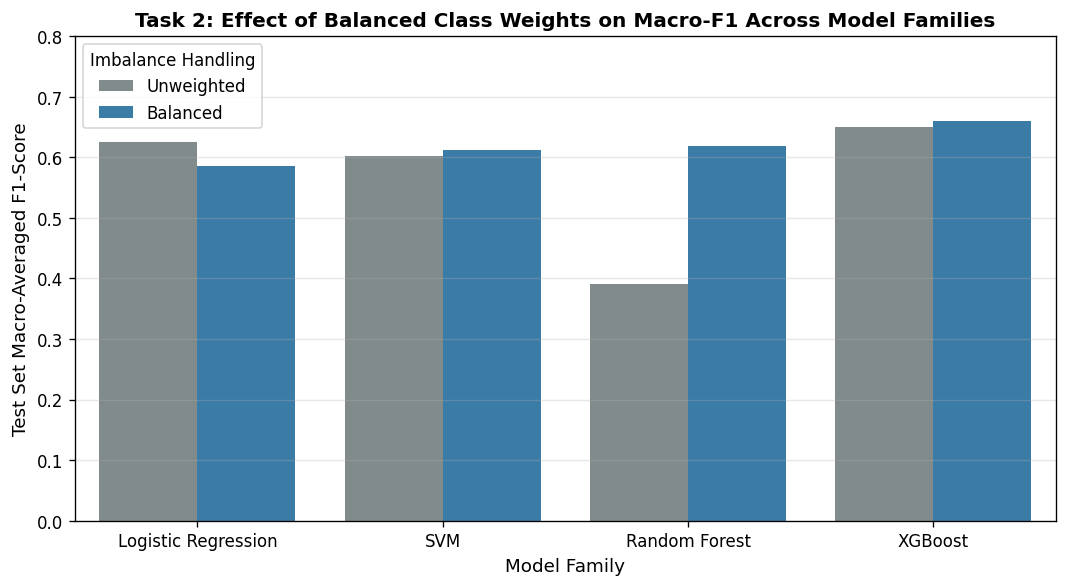

In [5]:
macro_df = pd.DataFrame(macro_results_rows)
print("\n================ TASK 2 MACRO-AVERAGED RESULTS TABLE ================")
print(macro_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Identify overall best model by Test Macro-F1
best_row = macro_df.sort_values(by="Macro_F1", ascending=False).iloc[0]
best_model_name = best_row["Model"]
best_setting_name = best_row["Setting"]
print(f"\nBest Overall Task 2 Model (by Macro-F1): {best_model_name} [{best_setting_name}] -> Macro-F1 = {best_row['Macro_F1']:.4f}, Accuracy = {best_row['Test_Accuracy']:.4f}")

# Grouped bar chart: Unweighted vs Balanced Macro-F1 across all 4 model families
plt.figure(figsize=(9, 5), dpi=120)
sns.barplot(
    data=macro_df, x="Model", y="Macro_F1", hue="Setting",
    palette={"Unweighted": "#7f8c8d", "Balanced": "#2980b9"}
)
plt.ylabel("Test Set Macro-Averaged F1-Score", fontsize=11)
plt.xlabel("Model Family", fontsize=11)
plt.title("Task 2: Effect of Balanced Class Weights on Macro-F1 Across Model Families", fontsize=12, fontweight="bold")
plt.ylim(0, 0.80)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Imbalance Handling")
plt.tight_layout()
plt.savefig("task2_imbalance_macro_f1_comparison.png", dpi=300)
plt.show()


# 6. Per-Class Precision, Recall & F1-Score (Unweighted vs. Balanced)



=== Per-Class Performance Breakdown for XGBoost: Unweighted vs. Balanced ===
        Precision              Recall            F1-Score           
Setting  Balanced Unweighted Balanced Unweighted Balanced Unweighted
Sigma                                                               
sigma70    0.8859     0.8377   0.8702     0.9440   0.8780     0.8877
sigma24    0.7222     0.7500   0.8041     0.7113   0.7610     0.7302
sigma32    0.6515     0.7091   0.7414     0.6724   0.6935     0.6903
sigma38    0.4286     0.8750   0.2727     0.2121   0.3333     0.3415
sigma28    0.6923     0.7500   0.6667     0.5556   0.6792     0.6383
sigma54    0.6111     0.6667   0.6111     0.5556   0.6111     0.6061

=== Full Classification Report: XGBoost (Balanced) ===
              precision    recall  f1-score   support

     sigma70     0.8859    0.8702    0.8780       339
     sigma24     0.7222    0.8041    0.7610        97
     sigma32     0.6515    0.7414    0.6935        58
     sigma38     0.4286    0

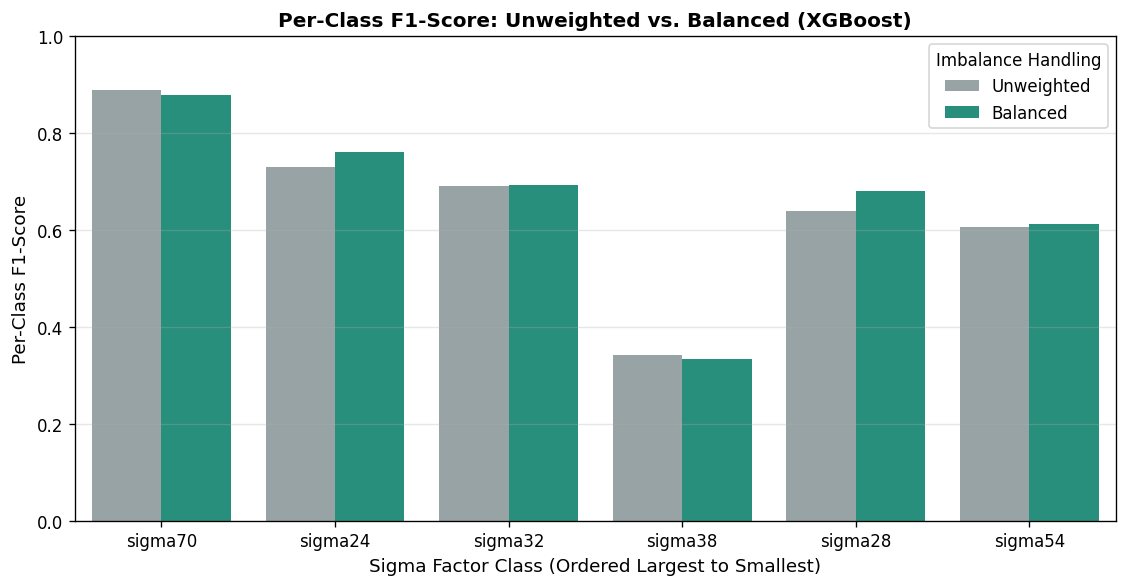

In [6]:
per_class_df = pd.DataFrame(per_class_records)

# Show detailed side-by-side per-class comparison for the best model family
best_family_pc = per_class_df[per_class_df["Model"] == best_model_name]
pivot_pc = best_family_pc.pivot(index="Sigma", columns="Setting", values=["Precision", "Recall", "F1-Score"]).loc[SIGMA_CLASSES]

print(f"\n=== Per-Class Performance Breakdown for {best_model_name}: Unweighted vs. Balanced ===")
print(pivot_pc.to_string(float_format=lambda x: f"{x:.4f}"))

# Also print the full scikit-learn classification report for the best model
best_clf_final = trained_models[best_setting_name][best_model_name]
y_pred_best = best_clf_final.predict(X_test_full)

print(f"\n=== Full Classification Report: {best_model_name} ({best_setting_name}) ===")
print(classification_report(y_test, y_pred_best, target_names=SIGMA_CLASSES, digits=4, zero_division=0))

# Plot per-class F1-score comparison (Unweighted vs Balanced) for the best model family
plt.figure(figsize=(9.5, 5), dpi=120)
sns.barplot(
    data=best_family_pc, x="Sigma", y="F1-Score", hue="Setting", order=SIGMA_CLASSES,
    palette={"Unweighted": "#95a5a6", "Balanced": "#16a085"}
)
plt.xlabel("Sigma Factor Class (Ordered Largest to Smallest)", fontsize=11)
plt.ylabel("Per-Class F1-Score", fontsize=11)
plt.title(f"Per-Class F1-Score: Unweighted vs. Balanced ({best_model_name})", fontsize=12, fontweight="bold")
plt.ylim(0, 1.0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Imbalance Handling")
plt.tight_layout()
plt.savefig("task2_per_class_f1_comparison.png", dpi=300)
plt.show()


# 7. 6x6 Confusion Matrix (Counts & Normalized Recall) + Error Pair Analysis


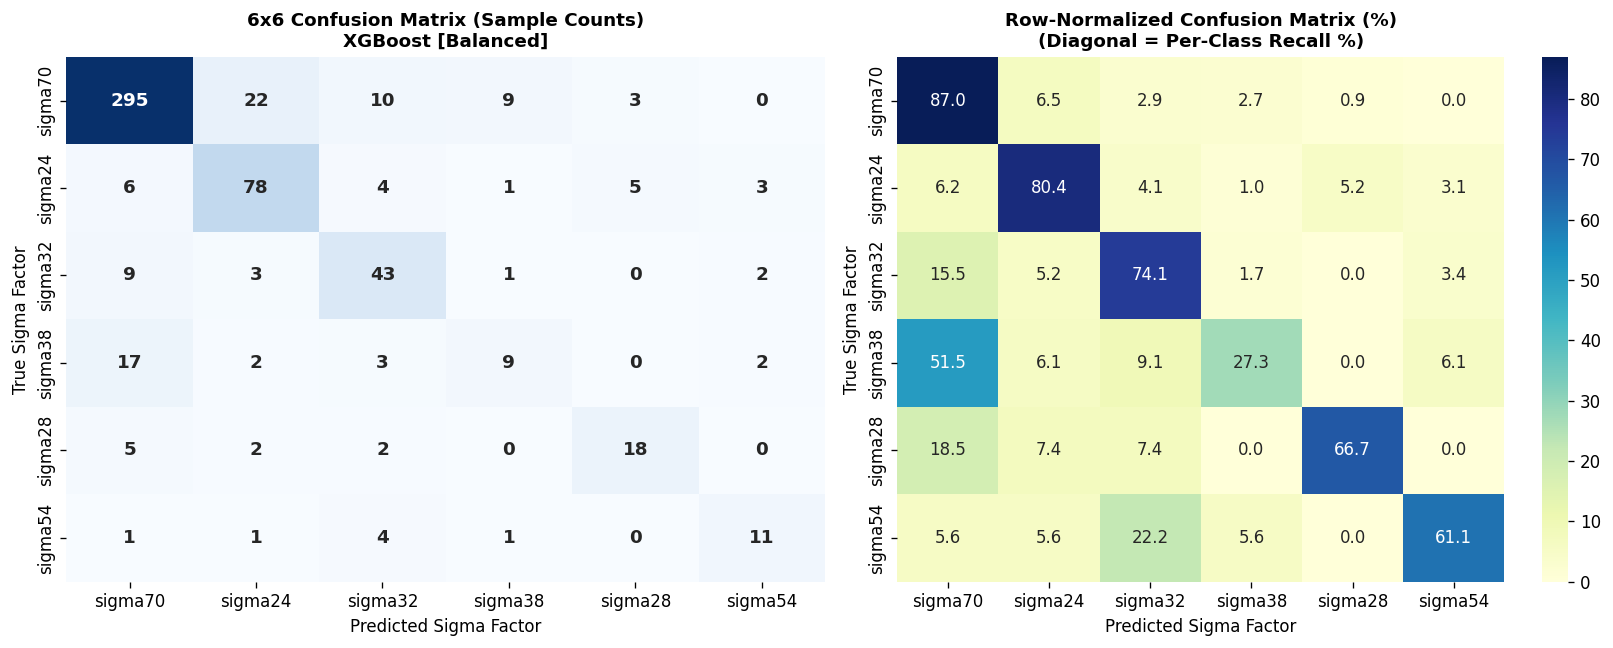

=== Top Misclassification / Confusion Pairs (Sorted by % of True Class) ===
True Class Predicted As  Misclassified Count  % of True Class
   sigma38      sigma70                   17            51.52
   sigma54      sigma32                    4            22.22
   sigma28      sigma70                    5            18.52
   sigma32      sigma70                    9            15.52
   sigma38      sigma32                    3             9.09
   sigma28      sigma32                    2             7.41
   sigma28      sigma24                    2             7.41
   sigma70      sigma24                   22             6.49


In [7]:
cm_counts = confusion_matrix(y_test, y_pred_best)
cm_norm   = cm_counts.astype(float) / cm_counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

# Left: Raw counts
sns.heatmap(
    cm_counts, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=SIGMA_CLASSES, yticklabels=SIGMA_CLASSES,
    annot_kws={"size": 11, "weight": "bold"}
)
axes[0].set_title(f"6x6 Confusion Matrix (Sample Counts)\n{best_model_name} [{best_setting_name}]", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted Sigma Factor")
axes[0].set_ylabel("True Sigma Factor")

# Right: Row-normalized percentages (per-class recall along diagonal)
sns.heatmap(
    cm_norm * 100.0, annot=True, fmt=".1f", cmap="YlGnBu", cbar=True, ax=axes[1],
    xticklabels=SIGMA_CLASSES, yticklabels=SIGMA_CLASSES,
    annot_kws={"size": 10}
)
axes[1].set_title("Row-Normalized Confusion Matrix (%)\n(Diagonal = Per-Class Recall %)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Predicted Sigma Factor")
axes[1].set_ylabel("True Sigma Factor")

plt.tight_layout()
plt.savefig("task2_confusion_matrix_6x6.png", dpi=300)
plt.show()

# Automatically summarize top confused pairs (off-diagonal errors)
confusion_pairs = []
for i in range(len(SIGMA_CLASSES)):
    row_total = cm_counts[i].sum()
    for j in range(len(SIGMA_CLASSES)):
        if i != j and cm_counts[i, j] > 0:
            confusion_pairs.append({
                "True Class": SIGMA_CLASSES[i],
                "Predicted As": SIGMA_CLASSES[j],
                "Misclassified Count": int(cm_counts[i, j]),
                "% of True Class": 100.0 * cm_counts[i, j] / row_total,
            })

conf_pairs_df = pd.DataFrame(confusion_pairs).sort_values(by="% of True Class", ascending=False)
print("=== Top Misclassification / Confusion Pairs (Sorted by % of True Class) ===")
print(conf_pairs_df.head(8).to_string(index=False, float_format=lambda x: f"{x:.2f}"))


# 8. Exporting Task 2 Results for Report & Section 3.5 Bonus CNN Comparison


In [8]:

macro_df.to_csv("task2_macro_metrics_table.csv", index=False)
per_class_df.to_csv("task2_per_class_metrics_table.csv", index=False)

with open("task2_results_for_bonus.pkl", "wb") as f:
    pickle.dump({
        "macro_df": macro_df,
        "per_class_df": per_class_df,
        "best_model_name": best_model_name,
        "best_setting_name": best_setting_name,
        "confusion_matrix": cm_counts,
        "sigma_classes": SIGMA_CLASSES,
    }, f)

print("Saved 'task2_macro_metrics_table.csv', 'task2_per_class_metrics_table.csv', and 'task2_results_for_bonus.pkl'.")

Saved 'task2_macro_metrics_table.csv', 'task2_per_class_metrics_table.csv', and 'task2_results_for_bonus.pkl'.
